In [1]:
import pandas as pd
df = pd.read_csv('data.csv')
df.dropna(inplace=True)
df

,temperature_c,humidity_%,half-cell_potential_v,surface_resistivity,surface_roughness
0,30,55,-0.0580,46.3,44.99
1,30,55,-0.0870,39.7,47.42
2,30,55,-0.0420,56.0,44.99
3,30,55,-0.1420,33.5,44.99
4,30,55,-0.0760,36.5,47.42
...,...,...,...,...,...
245,32,80,-0.3397,15.5,50.03
246,32,80,-0.2268,25.8,26.47
247,32,80,-0.5405,24.7,50.02
248,32,80,-0.5210,20.7,50.02


**confusion matrix**

                       temperature_c  humidity_%  half-cell_potential_v  \
temperature_c               1.000000    0.304465              -0.599430   
humidity_%                  0.304465    1.000000              -0.400347   
half-cell_potential_v      -0.599430   -0.400347               1.000000   
surface_resistivity        -0.423757   -0.197571               0.681702   
surface_roughness           0.178015   -0.136131              -0.156344   

                       surface_resistivity  surface_roughness  
temperature_c                    -0.423757           0.178015  
humidity_%                       -0.197571          -0.136131  
half-cell_potential_v             0.681702          -0.156344  
surface_resistivity               1.000000           0.017438  
surface_roughness                 0.017438           1.000000  


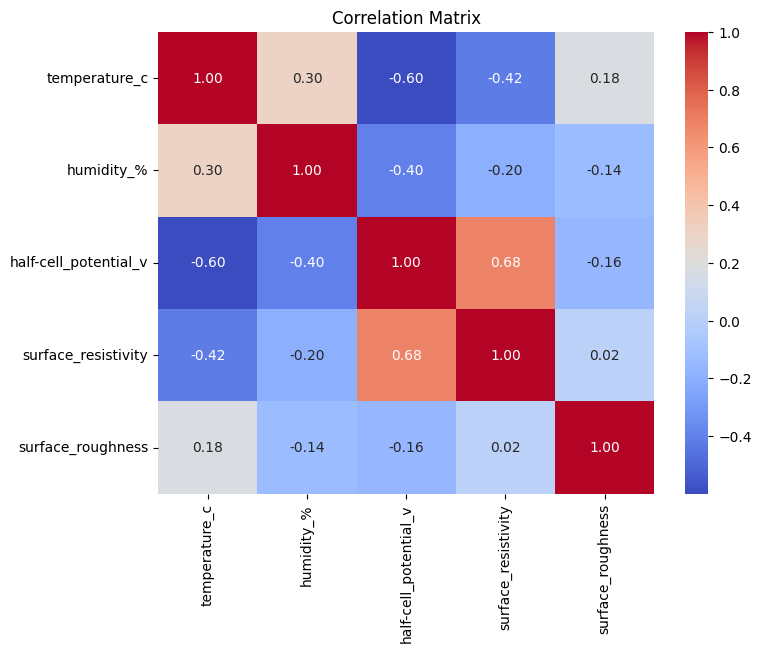

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
corr = df.corr()

# 2. Print correlation matrix
print(corr)

# 3. Visualize it
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [49]:
X = df.drop(columns=['half-cell_potential_v'])
y = df['half-cell_potential_v']

**Linear Regression**

R² score: 0.6748509328395049
Mean Absolute Error (MAE): 0.0536663173305739
Mean Squared Error (MSE): 0.00522302616817433
Root Mean Squared Error (RMSE): 0.07227050690409145


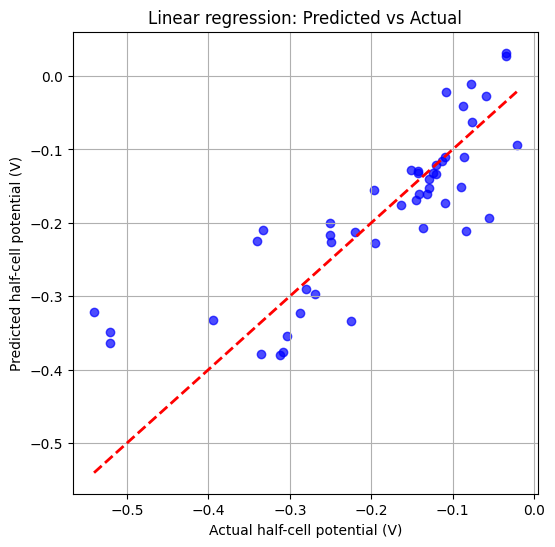

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train, y_train)
# Predictions
y_pred = model.predict(X_test)

# 1. R² score
r2 = model.score(X_test, y_test)
print("R² score:", r2)

# 2. Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print("Mean Absolute Error (MAE):", mae)

# 3. Mean Squared Error
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error (MSE):", mse)

# 4. Root Mean Squared Error
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual half-cell potential (V)")
plt.ylabel("Predicted half-cell potential (V)")
plt.title("Linear regression: Predicted vs Actual")
plt.grid(True)
plt.show()

**SVR**

SVR Performance:
----------------
R² score: 0.7865143684229391
Mean Absolute Error (MAE): 0.03893005603351316
Mean Squared Error (MSE): 0.00342932258730985
Root Mean Squared Error (RMSE): 0.058560418264471524


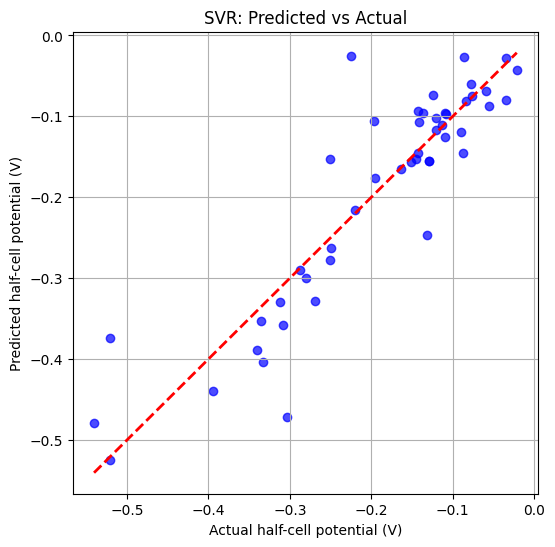

In [26]:
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 3. Scale features
# ======================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 4. Train SVR model
# ======================
# You can try kernel='linear' or kernel='rbf'
svr_model = SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.01)
svr_model.fit(X_train, y_train)

# ======================
# 5. Predictions
# ======================
y_pred = svr_model.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("SVR Performance:")
print("----------------")
print("R² score:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

# ======================
# 7. Optional: Predicted vs Actual plot
# ======================
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual half-cell potential (V)")
plt.ylabel("Predicted half-cell potential (V)")
plt.title("SVR: Predicted vs Actual")
plt.grid(True)
plt.show()


**Bayesian Ridge Regression**

Bayesian Ridge Regression Performance:
R²: 0.6752152891638793
MAE: 0.05337768406380091
MSE: 0.005217173336937979
RMSE: 0.07223000302462944


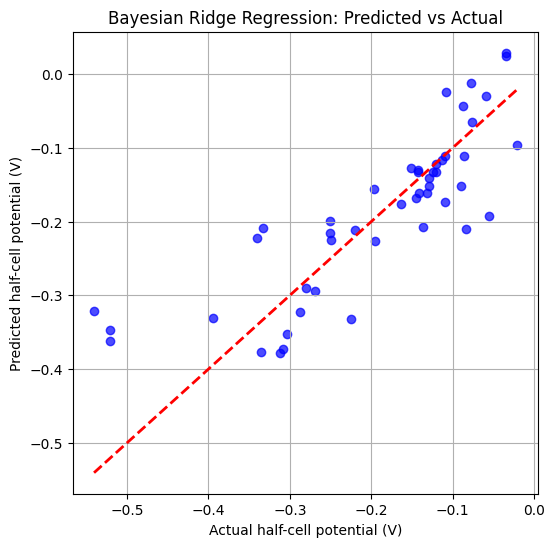

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train Bayesian Ridge Regression
model = BayesianRidge()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Bayesian Ridge Regression Performance:")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual half-cell potential (V)")
plt.ylabel("Predicted half-cell potential (V)")
plt.title("Bayesian Ridge Regression: Predicted vs Actual")
plt.grid(True)
plt.show()


**KNN**

Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV R²: 0.7070848288321002

KNN Regression Test Performance:
-------------------------------
R²: 0.831022140463288
MAE: 0.031020446762548948
MSE: 0.0027143727949454316
RMSE: 0.052099642944510006


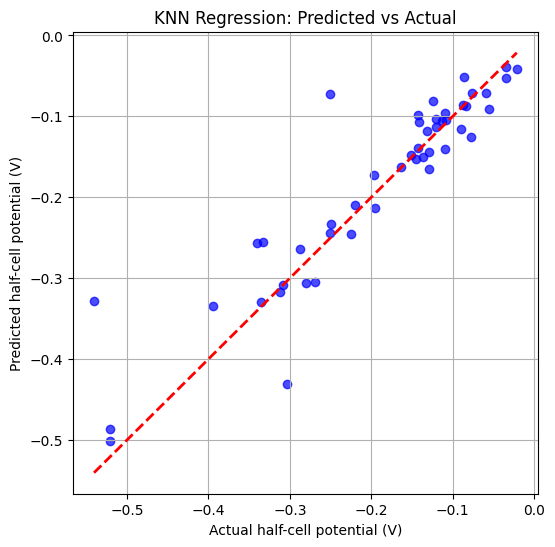

In [45]:
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 2. Scale features
# ======================
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 3. KNN Regressor + GridSearchCV
# ======================
knn = KNeighborsRegressor()

param_grid = {
    'n_neighbors': list(range(1, 21)),  # Test k from 1 to 20
    'weights': ['uniform', 'distance'],  # uniform or distance-weighted
    'p': [1, 2]  # p=1 -> Manhattan, p=2 -> Euclidean
}

grid_search = GridSearchCV(
    estimator=knn,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ======================
# 4. Best model & parameters
# ======================
best_knn = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 5. Predictions on test set
# ======================
y_pred = best_knn.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nKNN Regression Test Performance:")
print("-------------------------------")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

# ======================
# 7. Predicted vs Actual plot
# ======================
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual half-cell potential (V)")
plt.ylabel("Predicted half-cell potential (V)")
plt.title("KNN Regression: Predicted vs Actual")
plt.grid(True)
plt.show()


**Random forest**

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 30}
Best CV R²: 0.7297138957774052

Random Forest Regression Test Performance:
-------------------------------------------
R²: 0.807382641153986
MAE: 0.03266328349394341
MSE: 0.0030941054651735106
RMSE: 0.05562468395571799


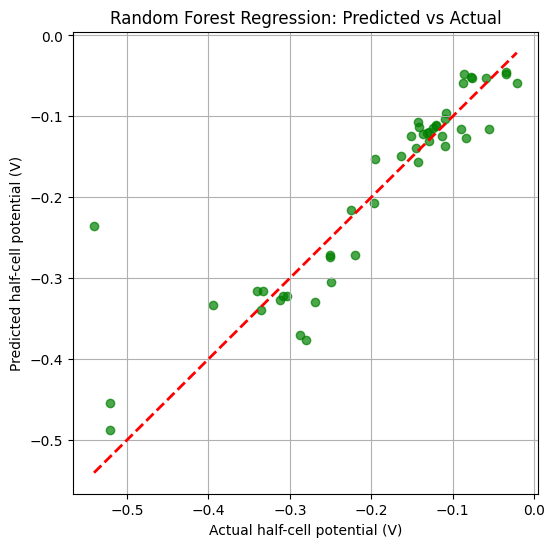

In [51]:
# Import libraries
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# ======================
# 1. Train/Test split
# ======================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ======================
# 2. Scaling (optional for tree-based models)
# ======================
# Random Forests do NOT require scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ======================
# 3. Random Forest + GridSearchCV
# ======================
rf = RandomForestRegressor(random_state=42)

param_grid = {
    'n_estimators': [30, 50, 70],   # small number of trees
    'max_depth': [3, 4, 5],         # shallow trees to avoid overfitting
    'min_samples_split': [2, 5],    # min samples to split a node
    'min_samples_leaf': [1, 2]      # min samples in leaf node
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='r2',
    cv=5,
    verbose=1
)

grid_search.fit(X_train, y_train)

# ======================
# 4. Best model & parameters
# ======================
best_rf = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best CV R²:", grid_search.best_score_)

# ======================
# 5. Predictions on test set
# ======================
y_pred = best_rf.predict(X_test)

# ======================
# 6. Evaluation
# ======================
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("\nRandom Forest Regression Test Performance:")
print("-------------------------------------------")
print("R²:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

# ======================
# 7. Predicted vs Actual plot
# ======================
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, color='green', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel("Actual half-cell potential (V)")
plt.ylabel("Predicted half-cell potential (V)")
plt.title("Random Forest Regression: Predicted vs Actual")
plt.grid(True)
plt.show()
